# Анализ E0


Анализ ведём на **val_b** — части, которая не участвовала в выборе числа деревьев.



- Самые сильные признаки — признаки пользователя 
- Внутри пользователя ранжируют другие признаки (трек, пара user×трек/артист) 
- Счётчики с исходом (дослушал/пропустил) сильнее, чем «слушал ли раньше» 
- Доли по редким трекам — шум 
- Чем отличается логрегрессия
- Сдвиг доли label к концу периода портит калибровку
- Качество на пользователях с короткой историей 

In [1]:
import sys, time, resource, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

import shap
from src.candidates import load_candidates
from src.features import E0_SPEC, E0_FEATURES
from src.metrics import evaluate
from sklearn.metrics import roc_auc_score, log_loss

ART = ROOT / "artifacts" / "E0"
res = pickle.load(open(ART / "results.pkl", "rb"))
lgb_model = pickle.load(open(ART / "lgb.pkl", "rb"))
lr_model = pickle.load(open(ART / "lr.pkl", "rb"))
GROUP_OF = {n: g for n, _, g, _ in E0_SPEC}

feats = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")
vb = (res["predictions"].filter(pl.col("part") == "val_b")
      .join(feats, on="row_id"))
print(f"val_b: {vb.height:,} строк".replace(",", " "))
res["metrics"].filter(pl.col("часть") == "val_b")

.../site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


val_b: 725 211 строк


модель,часть,logloss,roc_auc,ndcg@10,recall@10,gauc,groups
str,str,f64,f64,f64,f64,f64,i64
"""константа""","""val_b""",0.611353,0.5,0.716534,0.485897,0.5,15622
"""случайный""","""val_b""",0.963249,0.499925,0.716066,0.485771,0.500422,15622
"""u_full_rate_30d""","""val_b""",0.481151,0.804436,0.716534,0.485897,0.5,15622
"""LightGBM""","""val_b""",0.455769,0.825421,0.765118,0.510427,0.569026,15622
"""логрегрессия""","""val_b""",0.465139,0.819175,0.75773,0.506214,0.562303,15622


## 1.  gain

**Gain** — насколько в сумме признак уменьшил функцию потерь во всех разбиениях всех деревьев
 - она смещена к признакам с большим числом уникальных значений 
-  делит важность между коррелированными признаками.

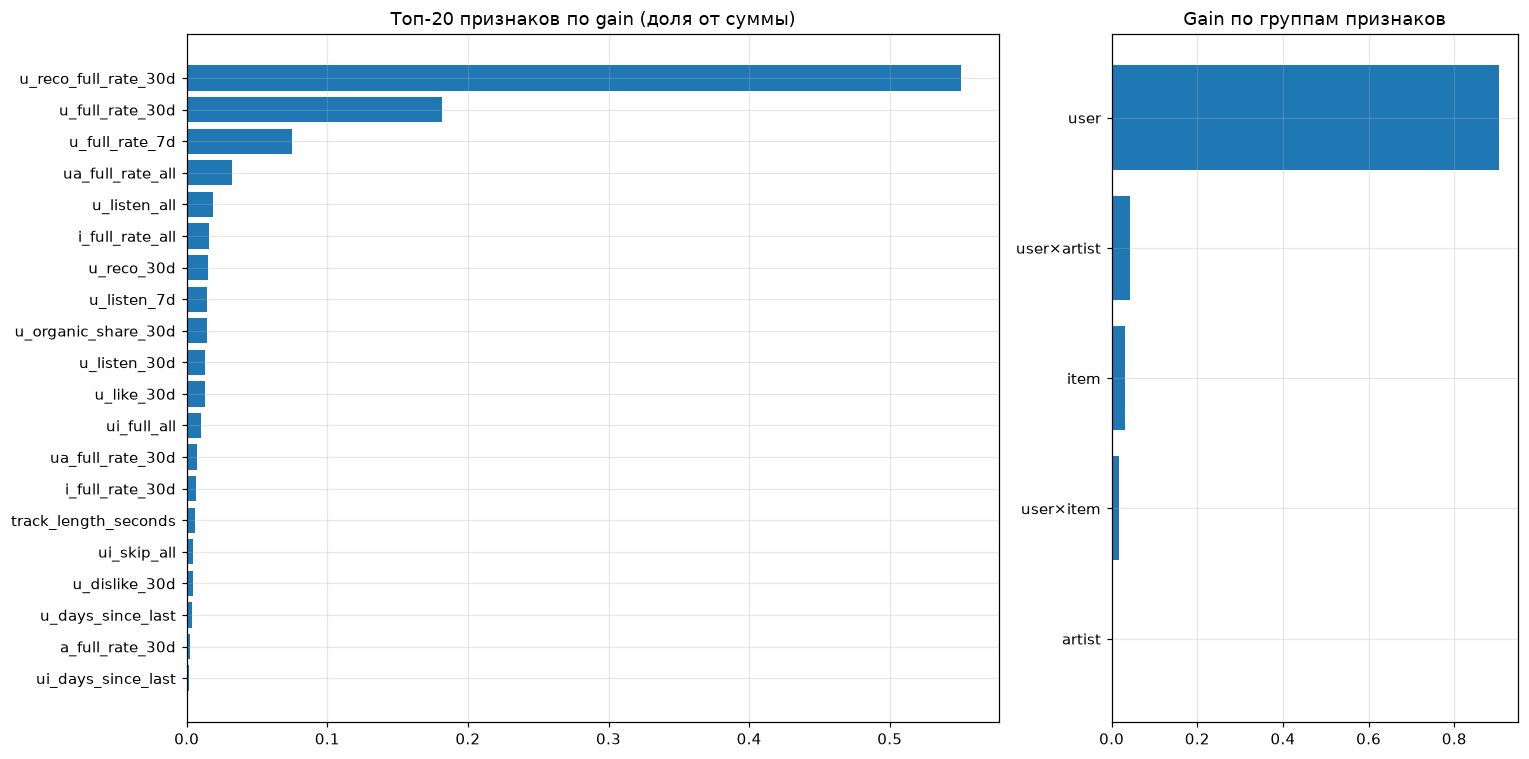

In [2]:
gain = pl.DataFrame({"признак": lgb_model.feature_name(), "gain": lgb_model.feature_importance("gain")})
gain = (gain.with_columns(pl.Series("признак", E0_FEATURES))      # в модели имена Column_i -> настоящие
        .with_columns((pl.col("gain") / pl.col("gain").sum()).alias("доля"),
                      pl.col("признак").replace_strict(GROUP_OF).alias("группа"))
        .sort("доля", descending=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [2, 1]})
g = gain.head(20).reverse()

axes[0].barh(g["признак"], g["доля"])
axes[0].set_title("Топ-20 признаков по gain (доля от суммы)")
gg = gain.group_by("группа").agg(pl.col("доля").sum()).sort("доля")

axes[1].barh(gg["группа"], gg["доля"])
axes[1].set_title("Gain по группам признаков")
plt.tight_layout()
plt.show()

## 2. SHAP

**SHAP-значение** признака для конкретной строки — насколько этот признак сдвинул предсказание этой строки относительно среднего (в единицах логита).

Берём выборку **целых групп** «пользователь × день» , а не рандом

.../site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


SHAP для 69 403 строк из 2 000 групп: 157 с


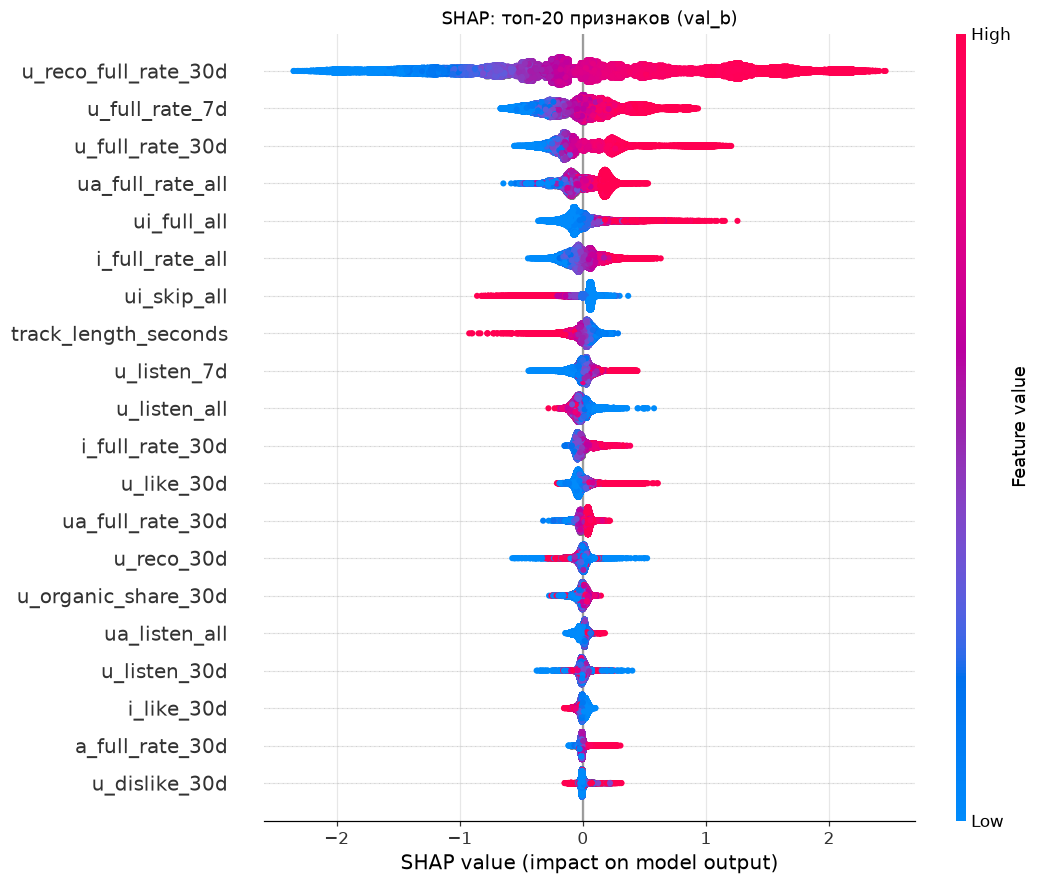

In [3]:
rng = np.random.default_rng(0)
groups = vb.select("uid", "day").unique().sort("uid", "day")
pick = groups[rng.choice(groups.height, 2000, replace=False)]
sample = vb.join(pick, on=["uid", "day"]).sort("uid", "day")
Xs = sample.select(E0_FEATURES).to_numpy()
t0 = time.perf_counter()
sv = shap.TreeExplainer(lgb_model).shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else sv
print(f"SHAP для {len(Xs):,} строк из 2 000 групп: {time.perf_counter() - t0:.0f} с".replace(",", " "))
shap.summary_plot(sv, Xs, feature_names=E0_FEATURES, max_display=20, show=False, plot_size=(10, 8))
plt.title("SHAP: топ-20 признаков (val_b)")
plt.show()

#### gain and shap
- train -> gain; val_b -> shap
- gain -> важен не важен, shap -> повышаетили понижает

- признаки пользователя доминируют и там и там
- пользователь * трек по gain не заметен, а по SHAP пто 10
- мб сильный эффект по малой доле строк дает маленький суммарный gain, но зм=аметный разброс по SHAP

- может gain недооценивает **редкие признаки, которые если уж включаются, так действуют** на полную, и для рекомендат сис надо бы их учитвывать!!!!!!!

## 3. Между пользователями или внутри пользователя

Разложим вклад каждого признака на две части:
- **общий вклад** — стандартное отклонение SHAP признака по всем строкам;
- **вклад внутри группы** — стандартное отклонение SHAP признака **внутри** группы «пользователь × день», усреднённое по группам.

Если признак сдвигает предсказания одинаково для всех треков пользователя за день, внутригрупповой вклад ≈ 0: на порядок треков он не влияет.
**Именно внутригрупповой вклад определяет NDCG и GAUC!!!!!!**

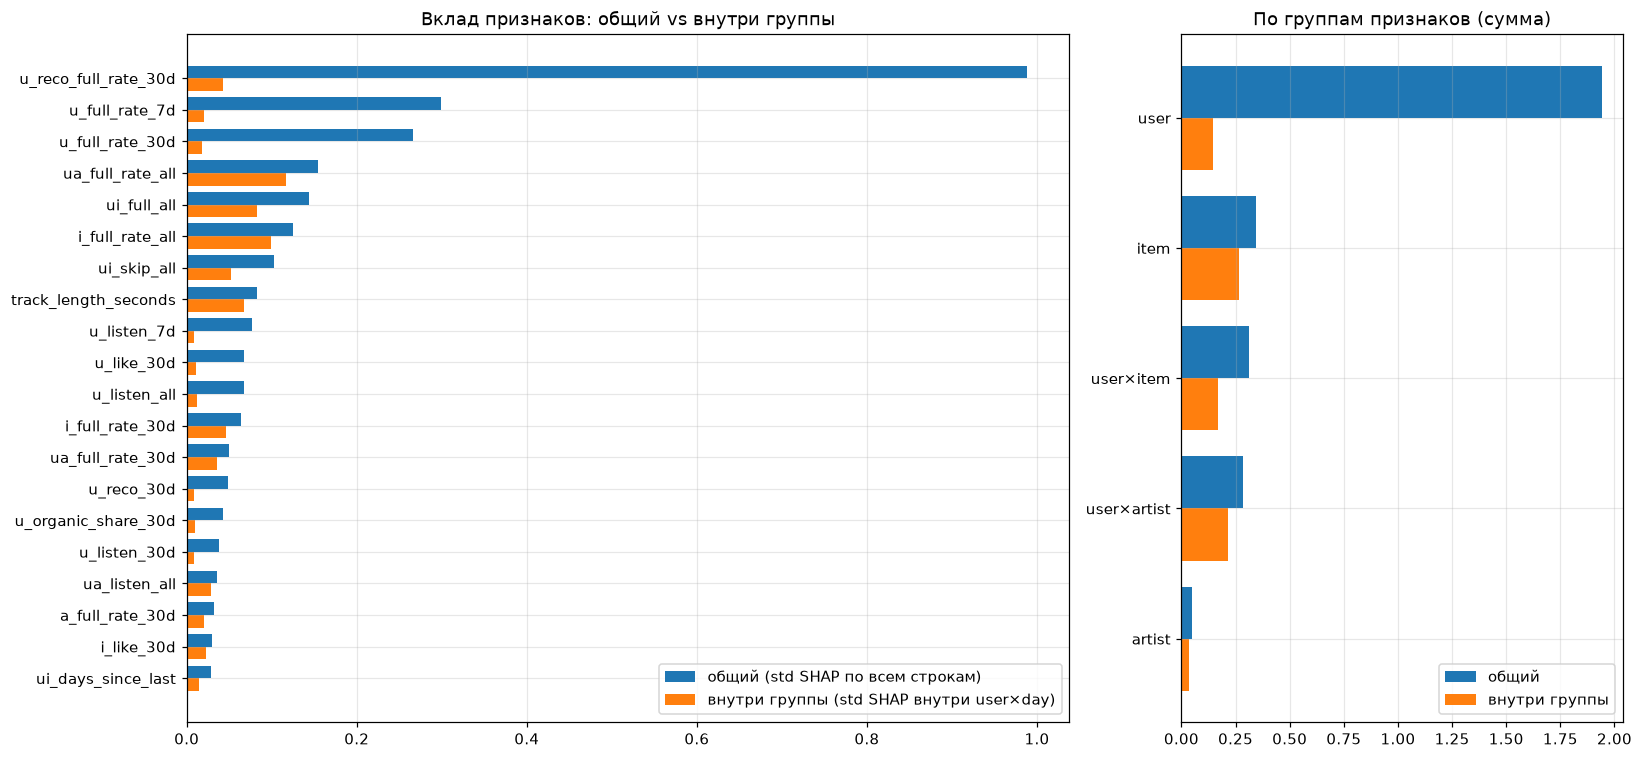

признак,общий,внутри группы,группа,доля внутри
str,f64,f64,str,f64
"""ua_full_rate_all""",0.154,0.117,"""user×artist""",0.762
"""i_full_rate_all""",0.126,0.099,"""item""",0.789
"""ui_full_all""",0.143,0.083,"""user×item""",0.577
"""track_length_seconds""",0.083,0.067,"""item""",0.805
"""ui_skip_all""",0.102,0.052,"""user×item""",0.508
"""i_full_rate_30d""",0.064,0.046,"""item""",0.725
"""u_reco_full_rate_30d""",0.989,0.042,"""user""",0.043
"""ua_full_rate_30d""",0.05,0.036,"""user×artist""",0.716
"""ua_listen_all""",0.036,0.029,"""user×artist""",0.814


In [4]:
S = pl.DataFrame(sv, schema=E0_FEATURES).with_columns(sample.select("uid", "day"))
total = S.select(pl.col(E0_FEATURES).std()).row(0)
within = (S.group_by("uid", "day").agg(pl.col(E0_FEATURES).std())
          .select(pl.col(E0_FEATURES).mean()).row(0))
dec = (pl.DataFrame({"признак": E0_FEATURES, "общий": total, "внутри группы": within})
       .with_columns(pl.col("признак").replace_strict(GROUP_OF).alias("группа"),
                     (pl.col("внутри группы") / pl.col("общий")).alias("доля внутри"))
       .sort("общий", descending=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [2, 1]})
d = dec.head(20).reverse()
y = np.arange(d.height)
axes[0].barh(y + 0.2, d["общий"], height=0.4, label="общий (std SHAP по всем строкам)")
axes[0].barh(y - 0.2, d["внутри группы"], height=0.4, label="внутри группы (std SHAP внутри user×day)")
axes[0].set_yticks(y, d["признак"])
axes[0].legend(loc="lower right")
axes[0].set_title("Вклад признаков: общий vs внутри группы")

grp = (dec.group_by("группа").agg(pl.col("общий").sum(), pl.col("внутри группы").sum()).sort("общий"))
yy = np.arange(grp.height)
axes[1].barh(yy + 0.2, grp["общий"], height=0.4, label="общий")
axes[1].barh(yy - 0.2, grp["внутри группы"], height=0.4, label="внутри группы")
axes[1].set_yticks(yy, grp["группа"])
axes[1].legend(loc="lower right")
axes[1].set_title("По группам признаков (сумма)")
plt.tight_layout()
plt.show()
display(dec.sort("внутри группы", descending=True).head(12).with_columns(pl.col(pl.Float64).round(3)))

- признаки пользователя дают огромный общий вклад, но внутри группы не ранжируют
- ВНУТРИ пользователя играют признаки **трека и пар**

## 4. Прямые связи: «слушал ли» против «чем закончилось»  и шум редких треков 

1) проверяем напрямую на данных val_b, без модели. 
- любил и люибт
- или ненавидит и пропускал все время

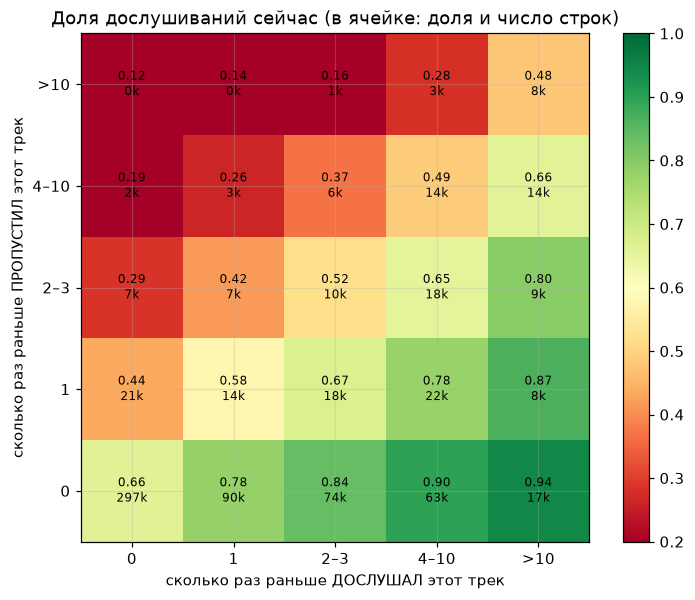

In [5]:
def bucket(col, edges, labels):
    e = pl.lit(labels[-1])
    for edge, lab in reversed(list(zip(edges, labels[:-1]))):
        e = pl.when(pl.col(col) <= edge).then(pl.lit(lab)).otherwise(e)
    return e

labs = ["0", "1", "2–3", "4–10", ">10"]
t = (vb.with_columns(full_b=bucket("ui_full_all", [0, 1, 3, 10], labs),
                     skip_b=bucket("ui_skip_all", [0, 1, 3, 10], labs))
     .group_by("full_b", "skip_b").agg(pl.col("label").mean().alias("rate"), pl.len().alias("n")))
M = np.full((5, 5), np.nan)
N = np.zeros((5, 5), int)
for r in t.iter_rows(named=True):
    i, j = labs.index(r["skip_b"]), labs.index(r["full_b"])
    M[i, j], N[i, j] = r["rate"], r["n"]


fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(M, cmap="RdYlGn", vmin=0.2, vmax=1.0, origin="lower")
for i in range(5):
    for j in range(5):
        if N[i, j] > 0:
            ax.text(j, i, f"{M[i, j]:.2f}\n{N[i, j]/1000:.0f}k", ha="center", va="center", fontsize=8)



ax.set_xticks(range(5), labs)
ax.set_yticks(range(5), labs)
ax.set_xlabel("сколько раз раньше ДОСЛУШАЛ этот трек")
ax.set_ylabel("сколько раз раньше ПРОПУСТИЛ этот трек")
ax.set_title("Доля дослушиваний сейчас (в ячейке: доля и число строк)")
plt.colorbar(im, ax=ax)
plt.show()

**Шум долей у редких треков:** насколько разбросана доля дослушиваний трека в зависимости от того, по скольким прослушиваниям она посчитана.

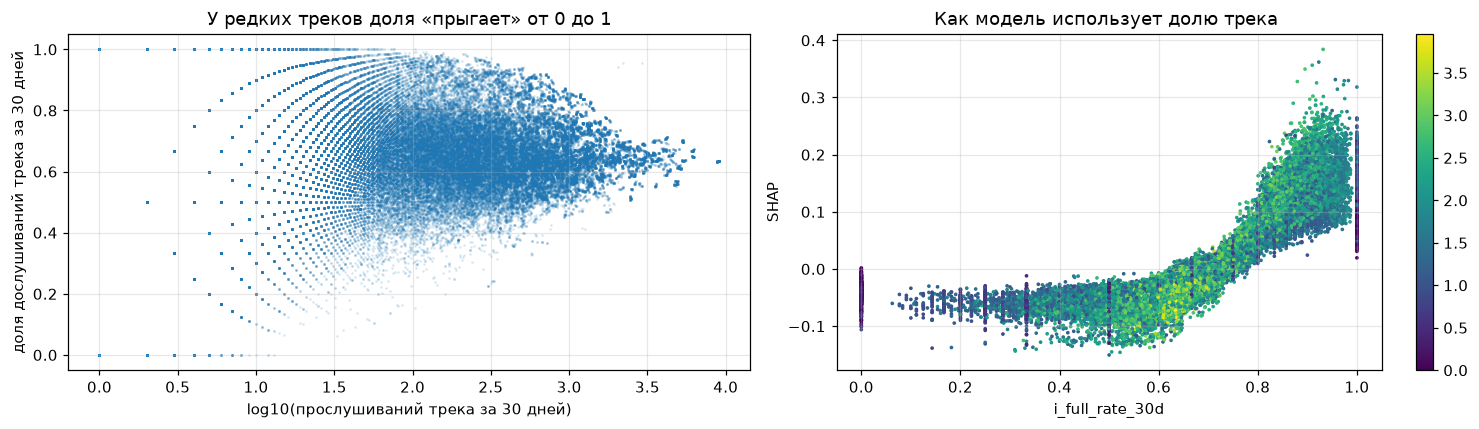

In [6]:
d = vb.filter(pl.col("i_full_rate_30d").is_not_null()).sample(100_000, seed=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))


axes[0].scatter(np.log10(d["i_listen_30d"].to_numpy()), d["i_full_rate_30d"].to_numpy(), s=1, alpha=0.1)
axes[0].set_xlabel("log10(прослушиваний трека за 30 дней)")
axes[0].set_ylabel("доля дослушиваний трека за 30 дней")
axes[0].set_title("У редких треков доля «прыгает» от 0 до 1")

idx = E0_FEATURES.index("i_full_rate_30d")
cnt = sample["i_listen_30d"].to_numpy()
ok = ~np.isnan(Xs[:, idx])
sc = axes[1].scatter(Xs[ok, idx], sv[ok, idx], c=np.log10(np.maximum(cnt[ok], 1)), s=2, cmap="viridis")


axes[1].set_xlabel("i_full_rate_30d")
axes[1].set_ylabel("SHAP")
#цвет — log10 числа прослушиваний
axes[1].set_title("Как модель использует долю трека ")
plt.colorbar(sc, ax=axes[1])
plt.tight_layout()
plt.show()

- слева данные - чем популярнее - тем доля надежнее, а не снизу и саерху
- справа модель - моедль примерно научилась не доверять доля рдедких треков, смотрит на счетчик рядом - хорошо
=> но можно попробовать еще сглаживание, тогда не надо моедли учить правило

## 5. Логистическая регрессия: веса признаков

После стандартизации веса можно сравнивать между собой: вес = насколько меняется логит при изменении признака на одно стандартное отклонение
- `missingindicator` — флаг «значение было пропущено» (нет истории)

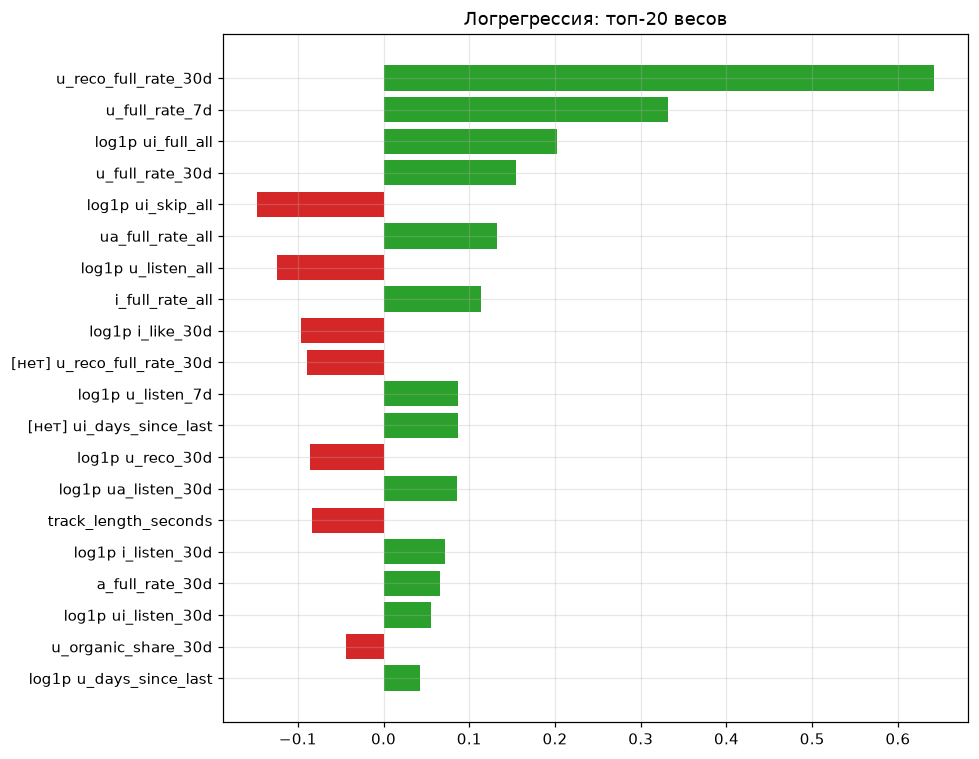

In [7]:
pre = lr_model[0]
names = pre.get_feature_names_out()

def readable(n):
    # имена вида "counts__x5" / "others__missingindicator_x12": x<N> — номер исходного признака
    kind, rest = n.split("__", 1)
    miss = rest.startswith("missingindicator_")
    f = E0_FEATURES[int(rest.rsplit("x", 1)[1])]
    return ("[нет] " if miss else ("log1p " if kind == "counts" else "")) + f



coef = (pl.DataFrame({"признак": [readable(n) for n in names], "вес": lr_model[-1].coef_[0]})
        .with_columns(pl.col("вес").abs().alias("|вес|")).sort("|вес|", descending=True))
c = coef.head(20).reverse()


plt.figure(figsize=(9, 7))
plt.barh(c["признак"], c["вес"], color=["tab:green" if v > 0 else "tab:red" for v in c["вес"]])
plt.title("Логрегрессия: топ-20 весов")
plt.tight_layout()
plt.show()

- у другой модели  веса (увеличение/уменьшение лог шанса) дают такие жде главные признаки как и SHAP
- НО у линейной модели есть прикол с корреливраонные признаками, у  i_like_30d вес отрицательный , а у i_listen_30d положительный, у них общий жффект распределен между ними каким-то образом

## 6. Калибровка и сдвиг доли label 

 модель с идеальной калибровкой лежит на диагонали
  Сравниваем val_a и val_b

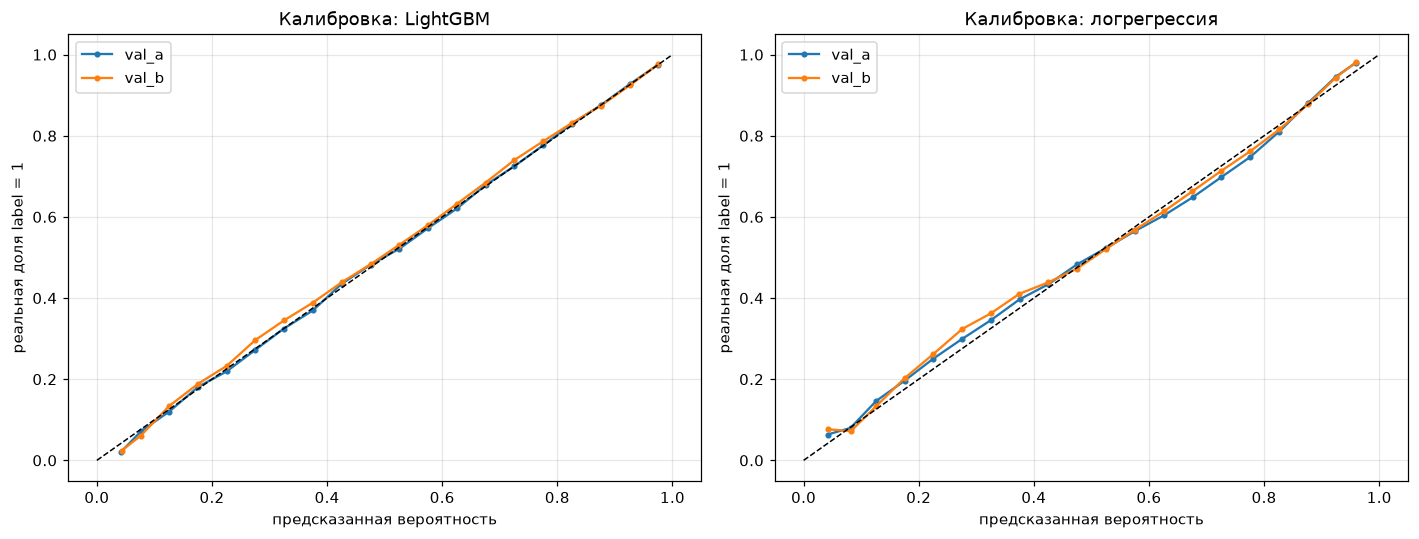

модель,часть,средний прогноз,реальная доля
str,str,f64,f64
"""LightGBM""","""val_a""",0.6885,0.6887
"""LightGBM""","""val_b""",0.6944,0.7003
"""логрегрессия""","""val_a""",0.6872,0.6887
"""логрегрессия""","""val_b""",0.6945,0.7003


In [8]:
preds = res["predictions"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rows = []


for ax, (m, col) in zip(axes, [("LightGBM", "p_lgb"), ("логрегрессия", "p_lr")]):
    for p in ["val_a", "val_b"]:

        d = preds.filter(pl.col("part") == p)
        cal = (d.with_columns((pl.col(col) * 20).floor().clip(0, 19).alias("bin"))
               .group_by("bin").agg(pl.col(col).mean().alias("pred"), pl.col("label").mean().alias("true"))
               .sort("bin"))
        
        ax.plot(cal["pred"], cal["true"], "o-", ms=3, label=p)
        rows.append({"модель": m, "часть": p, "средний прогноз": d[col].mean(), "реальная доля": d["label"].mean()})
    
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"Калибровка: {m}")
    ax.set_xlabel("предсказанная вероятность")
    ax.set_ylabel("реальная доля label = 1")
    ax.legend()



plt.tight_layout()
plt.show()
pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(4))

- бустинг хорошо справляется с калибровкой, все заложено в признаки

## 7. Где модель ошибается: сегменты (R9, R14)

Считаем метрики отдельно по сегментам val_b:
- **история пользователя**: сколько прослушиваний у пользователя за всё время к этому дню;
- **знакомость трека**: слушал ли пользователь этот трек раньше;
- **популярность трека**: сколько у трека прослушиваний за всё время (всеми пользователями).

GAUC и NDCG считаем только для сегментов по пользователю (группа «пользователь × день» целиком внутри сегмента). Для сегментов по треку — только LogLoss и ROC-AUC.

In [9]:
def seg_table(seg_expr, name, ranking):
    out = []
    d = vb.with_columns(seg=seg_expr)

    for s in d["seg"].unique().sort().to_list():
        x = d.filter(pl.col("seg") == s)
        row = {"сегмент": f"{name}: {s}", "доля строк": round(x.height / vb.height, 3),
               "доля label": round(x["label"].mean(), 3)}
        if ranking:
            m = evaluate(x, "p_lgb")
            row |= {k: round(v, 4) for k, v in m.items() if k != "groups"}
        else:
            yv, pv = x["label"].to_numpy(), x["p_lgb"].to_numpy()
            row |= {"logloss": round(log_loss(yv, pv), 4), "roc_auc": round(roc_auc_score(yv, pv), 4)}
        out.append(row)

    return out

rows = []
rows += seg_table(bucket("u_listen_all", [500, 2000, 8000], ["a) < 500", "b) 500–2k", "c) 2k–8k", "d) > 8k"]),
                  "история польз.", True)
rows += seg_table(pl.when(pl.col("ui_listen_all") > 0).then(pl.lit("знакомый")).otherwise(pl.lit("новый")),
                  "трек для польз.", False)
rows += seg_table(bucket("i_listen_all", [10, 100, 1000], ["a) < 10", "b) 10–100", "c) 100–1k", "d) > 1k"]),
                  "популярность трека", False)


pl.DataFrame(rows, infer_schema_length=None)

сегмент,доля строк,доля label,logloss,roc_auc,ndcg@10,recall@10,gauc
str,f64,f64,f64,f64,f64,f64,f64
"""история польз.: a) < 500""",0.043,0.676,0.5253,0.7645,0.7391,0.6164,0.5273
"""история польз.: b) 500–2k""",0.126,0.684,0.4866,0.8039,0.7527,0.5783,0.5441
"""история польз.: c) 2k–8k""",0.385,0.713,0.4457,0.8274,0.7756,0.5295,0.5692
"""история польз.: d) > 8k""",0.446,0.696,0.449,0.8345,0.7623,0.4441,0.5859
"""трек для польз.: знакомый""",0.591,0.726,0.4398,0.825,null,null,null
"""трек для польз.: новый""",0.409,0.663,0.4788,0.8227,null,null,null
"""популярность трека: a) < 10""",0.058,0.683,0.4228,0.8611,null,null,null
"""популярность трека: b) 10–100""",0.139,0.721,0.4147,0.8517,null,null,null
"""популярность трека: c) 100–1k""",0.371,0.708,0.4454,0.8313,null,null,null


- пользователь * день группа попадает цеклимо в сегмент
- пользователь * трек рвется, ранжировка пропадает - смысл ее

##### что видим
- чем длинее история, тем лучше модлеь
- для новых пользователь, почти сулчайный порядок
- модель одинаково хорошо работает на хнакомых и новых треках
- 


## 8. Выводы

| # | Гипотеза / опасение | Результат | Статус |
|---|---|---|---|
| H1 | Самые сильные признаки — признаки пользователя | Да: по SHAP группа «пользователь» даёт ~1.95 (сумма std SHAP) против ~0.3 у каждой из остальных групп. Главный признак — `u_reco_full_rate_30d`: как пользователь реагировал именно **на рекомендации**, а не на музыку вообще | ✅ |
| H9 | Внутри пользователя ранжируют другие признаки | Да: внутри группы «пользователь × день» основной вклад дают **трек** (`i_full_rate_all`, `track_length_seconds`), **пользователь × артист** (`ua_full_rate_all`) и **пользователь × трек** (`ui_full_all`, `ui_skip_all`). У признаков пользователя внутригрупповой вклад мал (4–7% от общего), он не нулевой только потому, что деревья комбинируют их с другими признаками | ✅ |
| H2 | Счётчики с исходом сильнее, чем «слушал ли раньше» | **Сильно да.** «Слушал / не слушал» даёт 0.64 → 0.70. Тепловая карта: трек, который дослушали > 10 раз и ни разу не пропустили, дослушивают в **94%** случаев; трек, который пропустили > 10 раз и ни разу не дослушали, — в **12%**. Разброс 0.12–0.94 вместо 0.64–0.70 | ✅ |
| R14 | Доли по редким трекам — шум | Шум виден («веер» на графике: при 1–10 прослушиваниях доля принимает значения 0, 1/2, 1/3, …). Модель отчасти научилась не доверять таким долям (крайние значения 0 и 1 у редких треков дают умеренный SHAP), опираясь на счётчик рядом. Сглаживание (H4) проверим в E1 | ⚠️ частично |
| R1 | Сдвиг доли label портит калибровку | Слабо: LightGBM откалиброван почти идеально; на val_b средний прогноз 0.694 при реальных 0.700 (недооценка на 0.6 п.п.). На test (0.714) недооценка будет больше, это ожидаемо и отмечается в отчёте | ⚠️ мало |
| R9 | Пользователи с короткой историей | Качество ниже: у пользователей с < 500 прослушиваний GAUC 0.527 и ROC-AUC 0.765, у пользователей с > 8 тыс. — 0.586 и 0.835. Это 4% строк | ✅ подтверждено |

**Ещё наблюдения:**
- **Длинные треки дослушивают реже** (`track_length_seconds`: большие значения → отрицательный SHAP). Логично: дослушать 50% шестиминутного трека труднее, чем трёхминутного.
- **Логрегрессия с коррелированными признаками:** у `i_like_30d` отрицательный вес, хотя лайки трека интуитивно «хороший» сигнал. Это эффект корреляции с `i_listen_30d`: веса линейной модели при коррелированных признаках нельзя читать по одному.
- **Редкие треки ранжируются не хуже популярных** (ROC-AUC 0.86 у треков с < 10 прослушиваниями против 0.81 у треков с > 1 тыс.). Вероятно, редкие треки рекомендуют более «предсказуемым» пользователям: сегменты по треку смешивают пользователей. Это не противоречит R14, но показывает, что шум долей не главный источник ошибок.
- **Recall@10 нельзя сравнивать между сегментами:** у активных пользователей группы больше (больше единиц), а в топ-10 помещается только 10, поэтому потолок Recall ниже.

**Что это даёт для E1 и E2:**
1. Семейства признаков **с исходом** (дослушал / пропустил / доля) — самые полезные для ранжирования. Грамматика обязательно должна их включать для всех ключей.
2. Признаки «реакция на рекомендации» (`reco_*`) сильнее, чем «реакция на всё», поэтому фильтр «органика / рекомендация» — обязательный слот грамматики.
3. Длина трека важна: её стоит добавить как ключ-модификатор («как пользователь дослушивает длинные треки»).
4. Отбор признаков в E1 оцениваем по **GAUC / NDCG** (рост ранжирования), а не только по LogLoss: иначе отбор заполнится признаками пользователя.
